# DataIO: シミュレーションの実行と、その raw データの再構成

SMILE-2+ のシミュレーションを EricaNext で実行し、出力を読み、実データと同じ形式で書き出した raw ファイルを
実データと同じ解析チェーンで再構成するまでを説明します。

```
設定ファイル config/simulation/*.json
        │
        ▼  run_script/run_sim.py(Geant4 + 検出器の応答)
        ├── edep.root               : Geant4 のエネルギー損失(真の値、1 一次粒子 1 行)
        └── raw/  uTPC_*.raw, HA*.raw : 実データと同じ形式の raw(トリガーのかかったイベント)
                  sim_truth.root      : raw のイベントの真の値(raw と 1 対 1)
                  Cal_HA*.dat         : 検出器の応答で使った HA の較正値
        │
        ▼  run_script/run_chain.py(実データと同じ再構成のチェーン)
        └── Reconstruct/single_hit  : 再構成ツリー
```

例として、気球高度(深さ 10 g/cm²)の **宇宙線の熱中性子** のシミュレーションを使います
(設定 `smile2p_flight_parma_thermal_neutron_d10_raw`)。SMILE_tool_box の参照の run
(`hikaru3_analysis2/BGsim/thermal_neutron_g10/simulation/d10`)と同じ設定で、エネルギー損失の分布、
raw の中身、再構成の結果が参照と合うことを確かめてあります(`docs/simulation_port_log.md`)。

各モジュールの中身(パラメータ、ほかのモジュールに渡す値と、それを取り出す関数)は `modules/` 以下のノートブックで個別に解説しています。

| 順 | モジュール | 解説 |
| --- | --- | --- |
| 1 | `SMILE2pGeometry` | `modules/1_SMILE2pGeometry/` |
| 2 | `SMILEPhysicsList` | `modules/2_SMILEPhysicsList/` |
| 3 | `ParmaCRPrimaryGen` | `modules/3_ParmaCRPrimaryGen/` |
| 4 | `EdepPickUp` | `modules/4_EdepPickUp/` |
| 5 | `SimTrigger` | `modules/5_SimTrigger/` |
| 6 | `TPCEmulator` | `modules/6_TPCEmulator/` |
| 7 | `HAEmulator` | `modules/7_HAEmulator/` |
| 8 | `RawWriter2p` | `modules/8_RawWriter2p/` |

> 実データの再構成の説明は `../../tutorials_caldata/1_DataIO/`、座標系は `../../tutorials_caldata/0_Introduction/` にあります。

In [1]:
import os, sys, shutil, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、実行スクリプト、設定ファイルの読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_sim.py").exists())
RUN_SIM = REPO / "run_script" / "run_sim.py"
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_simulation" / "cache"        # 出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    # RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列
    return np.stack([np.asarray(v) for v in column])

## 1. 準備

### 1.1 シミュレーションの環境

シミュレーションには Geant4 と anlgeant4(ComptonSoft)が要ります。実データの解析と同じ ANLNext(`~/opt/anlnext-g4`)で動き、
環境は `~/opt/setup_ericanext.sh` が設定します(入れ方と設定のしかたはリポジトリ直下の README の「インストール」)。
このノートブックは **カーネル「EricaNext」** で実行してください(環境変数がカーネルに書いてある)。
`source ~/opt/setup_ericanext.sh` したシェルから起動した Jupyter なら、ふつうの Python のカーネルでも動きます。下のセルで、ANLNext と anlgeant4 が読めるか確かめます。

In [2]:
import importlib.util
for m in ["anlnext", "anlgeant4"]:
    spec = importlib.util.find_spec(m)
    print("OK     " if spec else "MISSING", m, spec.origin if spec else "(source ~/opt/setup_ericanext.sh してから Jupyter を起動する)")
print("ANLNEXT_INSTALL:", os.environ.get("ANLNEXT_INSTALL"))

OK      anlnext /home/onoda/opt/anlnext-g4/lib/python/anlnext/__init__.py
OK      anlgeant4 /home/onoda/opt/comptonsoft/lib/python/anlgeant4/__init__.py
ANLNEXT_INSTALL: /home/onoda/opt/anlnext-g4


### 1.2 シミュレーションに使うデータ

| データ | 中身 | 置き場所 |
| --- | --- | --- |
| SMILE_tool_box_v2.20 の `data/` と `emulator_param/` | 形状(`SMILE_2p_Geo/*.mqo`)、HA の位置、Gd の捕獲のモデルの表、検出器の応答のテンプレート、シミュレーションの raw の再構成用のパラメータなど | NAS の `simulation_data/parameters/smile2p_sim_data`(設定ファイルの `{sim_data}`) |
| TPC のゲインマップ | 実データと同じ `Calibration20190130.dat`(TPC の応答の増幅率に使う) | NAS の `calibration_data/param/20190528`(`{data_top}/param/20190528`) |
| PARMA のフラックス | 入射させる宇宙線の、エネルギーと天頂角ごとのフラックス(`../5_PARMAFlux/`) | NAS の `simulation_data/parma_flux`(設定ファイルの `{parma_flux}`) |

NAS は研究室の EricaNext_try のデータの置き場(`/mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+`、`config/ericanext_config.py` の `DATA_DIR`)です。
NAS を読める計算機では何もしなくても動きます(NAS へのつなぎ方は、宇宙線研究室の hikaru / akari サーバーに VPN で接続。リポジトリ直下の README の「データの置き場所」)。
手元にコピーするときは同じ並びでコピーし、環境変数 `SMILE2P_DATA` に `calibration_data/` などがすぐ下にあるディレクトリ(NAS の `SMILE2+` にあたる)を設定して、カーネルを登録し直します
(`../../tutorials_caldata/1_DataIO/DataIO_example.ipynb` の 1 節)。
PARMA のフラックスの場所を変えたときは、設定ファイルの `source.flux_file` を書き換えるか、`run_sim.py --set source.flux_file=<パス>` で渡します。

設定ファイルが指すファイルがすべてあるか確かめます(`MISSING` があれば、NAS が読めるか、`SMILE2P_DATA` の場所を確かめる)。

In [3]:
CONFIG = "smile2p_flight_parma_thermal_neutron_d10_raw"
cfg = ec.load_sim(CONFIG)          # {sim_data} などを置き換え、"_" で始まるキー(コメント)を除いて読む
print("sim_data:", ec.sim_data())

def paths(obj, where=""):
    # 設定の中のファイル・ディレクトリのパス(絶対パス)を全部探す
    if isinstance(obj, dict):
        for k, v in obj.items():
            yield from paths(v, f"{where}.{k}" if where else k)
    elif isinstance(obj, list):
        for i, v in enumerate(obj):
            name = v.get("module", i) if isinstance(v, dict) else i
            yield from paths(v, f"{where}[{name}]")
    elif isinstance(obj, str) and obj.startswith("/"):
        yield where, obj

for where, p in paths(cfg):
    print("OK     " if Path(p).exists() else "MISSING", f"{where:45s}", p)

sim_data: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data
OK      environment.G4NEUTRONHPDATA                   /home/onoda/opt/geant4-data-extra/G4NDL4.7.1_Ar36fix
OK      detector.parameters.geometry_dir              /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/SMILE_2p_Geo
OK      detector.parameters.ha_position_file          /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/HA_Parameters_20190403_position_only/HAs.pos
OK      physics.parameters.gd155_table                /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/Gd_capture/Gd155.dat
OK      physics.parameters.gd157_table                /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/Gd_capture/Gd157_org.dat


OK      source.parameters.flux_file                   /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parma_flux/parma_flux_d10_g10_thermal.root
OK      pickup[EdepPickUp].parameters.ha_off_file     /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/HA_OFF.dat
OK      response[TPCEmulator].parameters.IwakiTemplate /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/IwakiTemp.root
OK      response[TPCEmulator].parameters.GainMap      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528/Calibration20190130.dat
OK      response[TPCEmulator].parameters.ClusterData  /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/cluster.txt
OK      response[HAEmulator].parameters.ChargeDivTemp /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/charge.div
OK      response[HAEmulator].parameters.P

## 2. 設定ファイル

シミュレーションの設定はすべて `config/simulation/smile2p_flight_parma_thermal_neutron_d10_raw.json` に書かれています
(書き方は `config/README.md`)。節ごとに、使うモジュール(`module`)とパラメータ(`parameters`)があり、
`run_sim.py` はこの順にモジュールをつなぎます。

| 節 | モジュール | 役割 |
| --- | --- | --- |
| `environment` | (環境変数) | Geant4 の中性子の反応のデータ(G4NDL)の場所 |
| `detector` | `SMILE2pGeometry` | SMILE-2+ の形状(flight: ゴンドラ込み)、ガスの圧力、HA の位置 |
| `physics` | `SMILEPhysicsList` | 物理モデル(電磁相互作用、中性子、Gd の中性子捕獲) |
| `source` | `ParmaCRPrimaryGen` | PARMA のフラックスに従って、検出器を囲む面から宇宙線を入射させる |
| `geant4` | `Geant4Body` | Geant4 の実行(乱数の種) |
| `pickup` | `EdepPickUp` | TPC のガス・シンチ・アンチでのエネルギー損失を記録(`edep.root`) |
| `response` | `SimTrigger` → `TPCEmulator` → `HAEmulator` → `RawWriter2p` | トリガー、TPC と HA の応答、raw ファイルの書き出し |

各モジュールのパラメータには、説明(`_doc`)と単位(`_units`)が付いています。例として `source` と `physics` を表示します
(`_doc` と `_units` は読み込むときに捨てるので、元の JSON から読みます)。

In [4]:
import json
raw_cfg = json.loads((REPO / "config" / "simulation" / f"{CONFIG}.json").read_text())

def show(section):
    entry = raw_cfg[section]
    p = entry["parameters"]
    print(f"[{section}] module = {entry['module']}")
    for k, v in p.items():
        if k.startswith("_"):
            continue
        unit = p.get("_units", {}).get(k, "")
        print(f"  {k} = {v}" + (f" [{unit}]" if unit else ""))
        print(f"      {p.get('_doc', {}).get(k, '')}")

show("source")
show("physics")

[source] module = ParmaCRPrimaryGen
  particle = neutron
      一次粒子(neutron, proton, e-, e+, gamma)
  flux_file = {parma_flux}/parma_flux_d10_g10_thermal.root
      PARMA のフラックスの ROOT ファイル(sim.mac の CR_FluxFile)
  plane_size = 300.0 [cm]
      粒子を出す正方形の面の一辺 [cm](sim.mac の ParaSrcSize [mm])
  plane_distance = 300.0 [cm]
      その面の原点からの距離 [cm](sim.mac の ParaSrcDistance [mm])
[physics] module = SMILEPhysicsList
  em_msc = gs
      e± の多重散乱: gs(Geant4 11 の G4EmLivermorePhysics)/ urban(SMILE_tool_box = Geant4 10.4 と同じ)
  gd_physics = True
      true: Gd の中性子捕獲のガンマを ANNRI-Gd 系のモデルで作る(sim.mac の GdPhysics 1)
  gd155_table = {sim_data}/Gd_capture/Gd155.dat
      Gd の捕獲のモデルの連続成分の表(Gd-155)
  gd157_table = {sim_data}/Gd_capture/Gd157_org.dat
      Gd の捕獲のモデルの連続成分の表(Gd-157)
  cut_value = 0.001 [mm]
      γ / e- / e+ の生成のカット(飛程)[mm]
  low_energy_limit = 0.25 [keV]
      カットの表のエネルギーの下限 [keV]


## 3. シミュレーションの実行

`run_script/run_sim.py` に設定ファイルを渡して実行します。ターミナルでは次のように打ちます。

```bash
cd run_script
python3 run_sim.py smile2p_flight_parma_thermal_neutron_d10_raw -n 1000000 --seed 1 -o edep.root --raw-dir raw
```

| 引数 | 意味 |
| --- | --- |
| 1 つ目 | 設定ファイル(`config/simulation/` の名前、または `.json` のパス) |
| `-n` | 一次粒子の数 |
| `--seed` | 乱数の種。同じ種なら同じ結果になる。統計を増やすときは種を変えて何回か実行する |
| `-o` | エネルギー損失のツリーのファイル |
| `--raw-dir` | raw ファイル、`sim_truth.root`、`Cal_HA*.dat` の出力先 |
| `--set 節.キー=値` | 設定ファイルの値をその場で上書き(例 `--set physics.em_msc=urban`) |

熱中性子は検出器でほとんど反応しないので、トリガーがかかって raw に書かれるのは **100 万個あたり約 230 イベント** です。
ここでは 100 万個を 1 回実行します(約 2000 個/秒で、約 10 分)。出力は `tutorials_simulation/cache/` に置き、
既にあれば実行しません。

In [5]:
SIM = CACHE / "d10_seed1_1M"
EDEP = SIM / "edep.root"
RAW = SIM / "raw"
cmd = [sys.executable, str(RUN_SIM), CONFIG, "-n", "1000000", "--seed", "1", "-o", str(EDEP), "--raw-dir", str(RAW)]
print(" ".join(cmd))
LOG = SIM / "run_sim.log"
if not (LOG.exists() and "RawWriter2p:" in LOG.read_text()):      # 最後まで実行したログが無ければ実行する
    SIM.mkdir(parents=True, exist_ok=True)
    with open(LOG, "w") as log:
        r = subprocess.run(cmd, stdout=log, stderr=subprocess.STDOUT, cwd=REPO / "run_script")
    r.check_returncode()
# ログの最後: トリガーのかかったイベント数と、raw に書いたイベント数
print("".join(l for l in open(LOG) if l.startswith(("SimTrigger:", "RawWriter2p:"))))

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_sim.py smile2p_flight_parma_thermal_neutron_d10_raw -n 1000000 --seed 1 -o /home/onoda/ANLNext/EricaNext_try/tutorials_simulation/cache/d10_seed1_1M/edep.root --raw-dir /home/onoda/ANLNext/EricaNext_try/tutorials_simulation/cache/d10_seed1_1M/raw
SimTrigger: daq_mode 3, collected 270 of 1000000 events
RawWriter2p: 270 events written to ../tutorials_simulation/cache/d10_seed1_1M/raw



`run_sim.py` がしていることは、設定ファイルの節の順にモジュールを ANLNext のチェーンにつないで実行するだけです。

```python
cfg = ericanext_config.load_sim("smile2p_flight_parma_thermal_neutron_d10_raw")
os.environ.update(cfg["environment"])                    # G4NEUTRONHPDATA
chain = anlnext.AnalysisChain()
for s in ["detector", "physics", "source", "geant4"]:   # SMILE2pGeometry, SMILEPhysicsList, ParmaCRPrimaryGen, Geant4Body
    chain.chain(cfg[s]["module"]); chain.with_parameters(cfg[s]["parameters"])
chain.chain(anlgeant4.StandardUserActionAssembly)
for e in cfg["pickup"] + cfg["response"]:               # EdepPickUp, SimTrigger, TPCEmulator, HAEmulator, RawWriter2p
    chain.chain(e["module"]); chain.with_parameters(e["parameters"])
chain.run(1000000)
```

## 4. エネルギー損失のツリー `edep`(`edep.root`)

Geant4 で、TPC のガス・シンチ・アンチにエネルギーを落としたステップをイベントごとに記録したツリーです。
**TPC かシンチにエネルギーを落としたイベントだけ** が入ります(`EdepPickUp.keep_empty_events = true` で全イベント)。
検出器の応答をかける前の真の値で、トリガーの条件もかかっていません。

| 分岐 | 型 | 中身 |
| --- | --- | --- |
| `event_id` | int | Geant4 のイベント番号(0 から、一次粒子の通し番号) |
| `primary_name`, `primary_energy` | string, double | 一次粒子の種類、運動エネルギー [keV] |
| `primary_pos[3]`, `primary_dir[3]` | double | 一次粒子の発生位置 [mm]、方向(長さ 1) |
| `e_tpc`, `e_scinti`, `e_anti` | double | TPC のガス・シンチ(全 HA の和)・アンチに落としたエネルギーの合計 [keV] |
| `tpc_e`, `tpc_x`, `tpc_y`, `tpc_z` | vector | TPC のガスでのステップごとのエネルギー損失 [keV] と位置 [mm] |
| `tpc_track`, `tpc_pdg`, `tpc_creator` | vector | そのステップの飛跡の番号、粒子(PDG コード: 11 = 電子など)、飛跡を作った過程(一次粒子は `primary`) |
| `sci_volume`, `sci_copy` | vector | シンチのステップの立体の名前とコピー番号(どの HA のどのピクセルか) |
| `sci_e`, `sci_x`, `sci_y`, `sci_z` | vector | シンチでのステップごとのエネルギー損失 [keV] と位置 [mm] |

位置は検出器の座標系(`../../tutorials_caldata/0_Introduction/`)で、ステップの終点の位置です。

In [6]:
df = ROOT.RDataFrame("edep", str(EDEP))
d = df.AsNumpy(["e_tpc", "e_scinti", "e_anti", "primary_energy"])
e_tpc, e_sci, e_anti, e0 = d["e_tpc"], d["e_scinti"], d["e_anti"], d["primary_energy"]
print("一次粒子: 1000000 個、そのうち TPC かシンチにエネルギーを落としたイベント:", len(e_tpc))
print("  TPC だけ:", np.sum((e_tpc > 0) & (e_sci == 0)), " シンチだけ:", np.sum((e_tpc == 0) & (e_sci > 0)),
      " 両方:", np.sum((e_tpc > 0) & (e_sci > 0)))

一次粒子: 1000000 個、そのうち TPC かシンチにエネルギーを落としたイベント: 9193
  TPC だけ: 40  シンチだけ: 8883  両方: 270


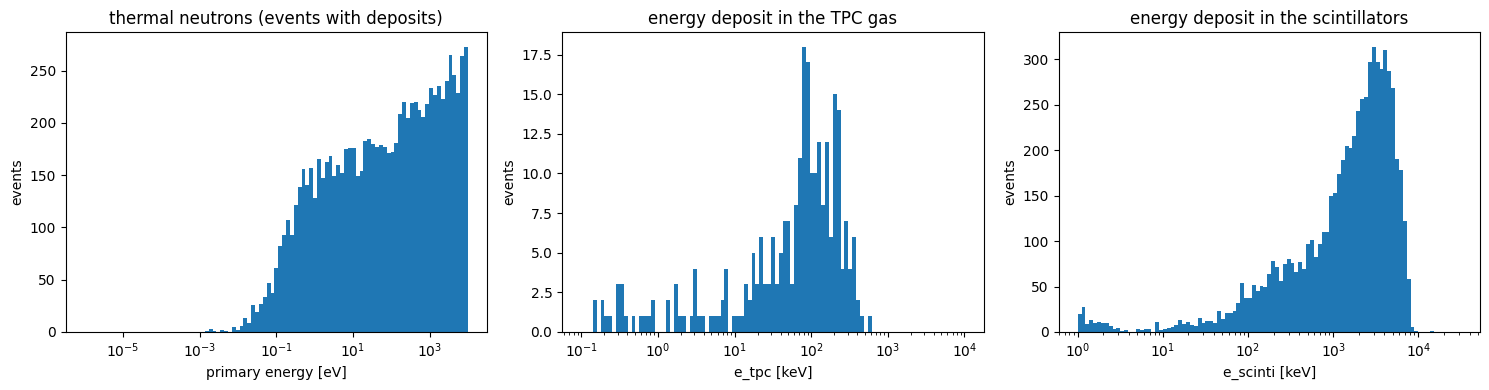

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(e0 * 1e3, bins=np.logspace(-6, 4, 100)); ax[0].set_xscale("log")
ax[0].set_xlabel("primary energy [eV]"); ax[0].set_title("thermal neutrons (events with deposits)")
ax[1].hist(e_tpc[e_tpc > 0], bins=np.logspace(-1, 4, 100)); ax[1].set_xscale("log")
ax[1].set_xlabel("e_tpc [keV]"); ax[1].set_title("energy deposit in the TPC gas")
ax[2].hist(e_sci[e_sci > 0], bins=np.logspace(0, 4.5, 100)); ax[2].set_xscale("log")
ax[2].set_xlabel("e_scinti [keV]"); ax[2].set_title("energy deposit in the scintillators")
for x in ax: x.set_ylabel("events")
fig.tight_layout(); plt.show()

- PARMA の「熱中性子」のフラックスファイルは、1 meV〜10 keV(1e-9〜0.01 MeV)の中性子です。
  左の図はエネルギーを落としたイベントだけの一次粒子のエネルギーです。
- 中性子そのものはほとんどエネルギーを落としません。エネルギーを落とすのは、中性子が原子核に吸収されたとき
  (Gd などの捕獲)に出るガンマ線と、それが TPC のガスで叩き出した電子です。
- シンチのエネルギー損失が数 MeV まで広がるのは、捕獲のガンマ線のエネルギーが数 MeV あるためです。

ステップごとの記録を使うと、1 イベントの飛跡を描けます。TPC に一番多くエネルギーを落としたイベントを描きます。

event_id 367699: e_tpc = 549.0 keV, steps = 7812, particles (PDG) = [11]


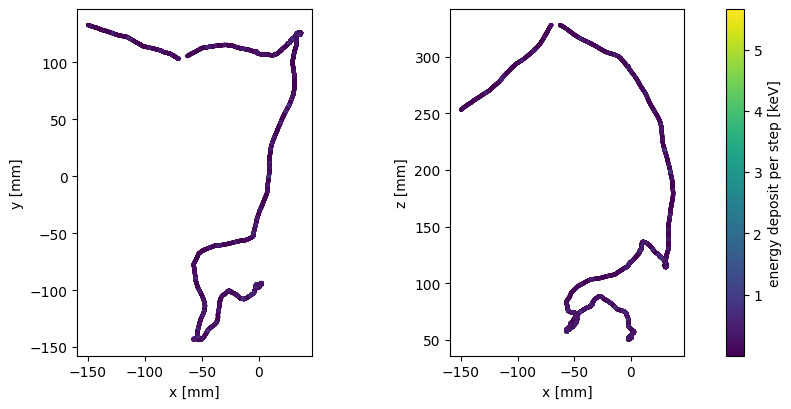

In [8]:
i = int(np.argmax(e_tpc))
ev = df.Range(i, i + 1).AsNumpy(["event_id", "tpc_e", "tpc_x", "tpc_y", "tpc_z", "tpc_pdg"])
te, tx, ty, tz, pdg = (np.asarray(ev[k][0]) for k in ["tpc_e", "tpc_x", "tpc_y", "tpc_z", "tpc_pdg"])
print(f"event_id {ev['event_id'][0]}: e_tpc = {e_tpc[i]:.1f} keV, steps = {len(te)}, particles (PDG) = {sorted(set(pdg.tolist()))}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (u, v, lu, lv) in zip(ax, [(tx, ty, "x", "y"), (tx, tz, "x", "z")]):
    s = a.scatter(u, v, c=te, s=4, cmap="viridis"); a.set_xlabel(f"{lu} [mm]"); a.set_ylabel(f"{lv} [mm]"); a.set_aspect("equal")
fig.colorbar(s, ax=ax, label="energy deposit per step [keV]"); plt.show()

## 5. raw ファイルと真の値(`raw/`)

`response` の節のモジュールが、トリガーのかかったイベントだけを実データと同じ形式で書き出します。

| モジュール | SMILE_tool_box | すること |
| --- | --- | --- |
| `SimTrigger` | `DAQ_Mode` | イベントを集める条件(`daq_mode = 3`: TPC とシンチの両方にエネルギー損失があるとき、実データの ETCC モード) |
| `TPCEmulator` | `TPC_emulator` | TPC のエネルギー損失 → 電離、拡散、GEM と µ-PIC の増幅、閾値 → エンコーダのヒットと FADC の波形 |
| `HAEmulator` | `Emu_HA` | シンチのエネルギー損失 → ピクセルごとの分解能、電荷分割 → HA の ADC。使った較正値を `Cal_HA*.dat` に書く |
| `RawWriter2p` | `EmuWrite2p` | 実データと同じ形式の raw ファイル(`uTPC_anode/cathode*.raw`、`HA*.raw`)と真の値 `sim_truth.root` を書く |

`sim_truth.root` のツリー `sim` は raw に書いたイベントと 1 対 1 で、同じ順に並んでいます。

| 分岐 | 中身 |
| --- | --- |
| `EventID` | Geant4 のイベント番号(`edep` の `event_id`) |
| `SrcEng` | 一次粒子のエネルギー [keV] |
| `SrcPos[3]`, `SrcDir[3]` | 一次粒子の発生位置 [mm]、方向 |
| `E_tpc`, `E_psa`, `E_anti` | TPC・シンチ・アンチに落としたエネルギー [keV](応答をかける前の真の値) |

In [9]:
for p in sorted(RAW.iterdir())[:6] + ["..."] + sorted(RAW.iterdir())[-4:]:
    print(p if p == "..." else f"{p.name:28s} {p.stat().st_size:>10,d} bytes")
truth = ROOT.RDataFrame("sim", str(RAW / "sim_truth.root")).AsNumpy(["EventID", "SrcEng", "E_tpc", "E_psa", "E_anti"])
print("raw に書いたイベント:", len(truth["EventID"]))

Cal_HA01.dat                      7,354 bytes
Cal_HA02.dat                      7,363 bytes
Cal_HA03.dat                      7,371 bytes
Cal_HA07.dat                      4,716 bytes
Cal_HA08.dat                      7,364 bytes
Cal_HA09.dat                      7,350 bytes
...
uTPC_anode3_00000.raw         1,467,100 bytes
uTPC_cathode1_00000.raw       1,480,000 bytes
uTPC_cathode2_00000.raw       1,438,900 bytes
uTPC_cathode3_00000.raw       1,410,280 bytes


raw に書いたイベント: 270


## 6. raw の再構成

シミュレーションの raw は、実データと同じ `run_chain.py` で再構成します。設定ファイルは `config/smile2p_sim_d10_recon.json` で、
参照のシミュレーションの再構成(SMILE_tool_box)と同じパラメータです。実データの設定との違いは次のとおりです。

| | 実データ(`smile2p_20190701_Per02`) | シミュレーション(`smile2p_sim_d10_recon`) |
| --- | --- | --- |
| `ReadData.data_dir` | 測定の raw | `--set ReadData.data_dir=<raw の場所>` で渡す |
| `ReadData.reverse_TPC` | `false` | `true`(エミュレータのストリップの並びに合わせる) |
| `HA_Calc.Emu_Mode` | `false` | `true`(エミュレータの PMT・ピクセルの番号の付け方に合わせる) |
| `HA_Calc.parameter_dir` | 測定の HA の較正 | エミュレータ用の較正(下で作る) |
| `TOT_Skewness.drift_velocity_file` | 測定から求めたドリフト速度 | エミュレータに入れたドリフト速度 |

### 6.1 再構成用のパラメータ

HA の較正とドリフト速度は、測定のものではなく、**シミュレーションの検出器の応答に入れた値** を使います。
`HA_Calc.parameter_dir`(`{sim_data}/emulator_param`)に次のファイルを置きます。無ければここで作ります。

| ファイル | 作り方 |
| --- | --- |
| `XMDF_HA*.dat`, `YMDF_HA*.dat` | エミュレータの電荷分割の MDF(`{sim_data}/XMDF.dat`, `YMDF.dat`、全 HA 共通)の写し |
| `Cal_HA*.dat` | `HAEmulator` が raw と一緒に書いたもの(run によらず同じ) |
| `HAs.pos` | 実データと同じ HA の位置(`{data_top}/param/20190528/HAs.pos`) |
| `drift_velocity.dat` | 1 行目に offset(`TPCEmulator.Offset_for_ETCC` = 85 clock)、以降 時間 [hour] と速度 [mm/clock]。速度は `TPCEmulator.DriftVel` = 38 µm/ns × 10 ns/clock = 0.38 mm/clock(時間によらず一定) |

In [10]:
RECON_CONFIG = "smile2p_sim_d10_recon"
rcfg = ec.load(RECON_CONFIG)
PARAM = Path(rcfg["parameters"]["HA_Calc"]["parameter_dir"])
tpc_emu = next(e["parameters"] for e in cfg["response"] if e["module"] == "TPCEmulator")
data_param = Path(ec.load("smile2p_20190701_Per02")["parameters"]["HA_Calc"]["parameter_dir"])

if not PARAM.exists():
    PARAM.mkdir(parents=True)
    for cal in sorted(RAW.glob("Cal_HA*.dat")):
        ha = cal.name[len("Cal_HA"):-len(".dat")]          # HA の名前(01, 02, ...)
        shutil.copy(cal, PARAM / cal.name)
        shutil.copy(ec.sim_data() / "XMDF.dat", PARAM / f"XMDF_HA{ha}.dat")
        shutil.copy(ec.sim_data() / "YMDF.dat", PARAM / f"YMDF_HA{ha}.dat")
    shutil.copy(data_param / "HAs.pos", PARAM / "HAs.pos")
    v = tpc_emu["DriftVel"] * 10 / 1000                   # µm/ns × 10 ns/clock → mm/clock
    lines = [str(tpc_emu["Offset_for_ETCC"])] + [f"{h / 6:.6f}\t{v:.2f}" for h in range(30)]   # 10 分ごと、5 時間分
    (PARAM / "drift_velocity.dat").write_text("\n".join(lines) + "\n")
print(PARAM)
print(sorted(p.name for p in PARAM.iterdir())[:4], "...", len(list(PARAM.iterdir())), "files")
print((PARAM / "drift_velocity.dat").read_text().splitlines()[:3])

/mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/simulation_data/parameters/smile2p_sim_data/emulator_param
['Cal_HA01.dat', 'Cal_HA02.dat', 'Cal_HA03.dat', 'Cal_HA07.dat'] ... 58 files
['85', '0.000000\t0.38', '0.166667\t0.38']


### 6.2 再構成の実行

ターミナルでは次のように打ちます。

```bash
cd run_script
python3 run_chain.py smile2p_sim_d10_recon -o sim_recon.root --set ReadData.data_dir=<raw の場所>
```

In [11]:
RECON = SIM / "recon.root"
cmd = [sys.executable, str(RUN_CHAIN), RECON_CONFIG, "-o", str(RECON), "--set", f"ReadData.data_dir={RAW}"]
print(" ".join(cmd))
if not RECON.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_sim_d10_recon -o /home/onoda/ANLNext/EricaNext_try/tutorials_simulation/cache/d10_seed1_1M/recon.root --set ReadData.data_dir=/home/onoda/ANLNext/EricaNext_try/tutorials_simulation/cache/d10_seed1_1M/raw


## 7. 再構成の結果と真の値

再構成ツリー `Reconstruct/single_hit` の分岐は実データと同じです(`../../tutorials_caldata/1_DataIO/` の 5 節)。
raw のイベントと 1 対 1 なので、`sim_truth.root` と行ごとに並べて比べられます。
解析に使うのは `err_flag == 0`(シングルヒットとして再構成できた)の行だけです。

In [12]:
rec = ROOT.RDataFrame("Reconstruct/single_hit", str(RECON)).AsNumpy(["err_flag", "Eg", "Ke", "Len_TRA"])
n = len(rec["err_flag"])
print("再構成ツリーの行:", n, " raw のイベント:", len(truth["EventID"]))
ok = rec["err_flag"] == 0
print(f"err_flag == 0: {ok.sum()} ({ok.mean():.1%})")

再構成ツリーの行: 270  raw のイベント: 270
err_flag == 0: 48 (17.8%)


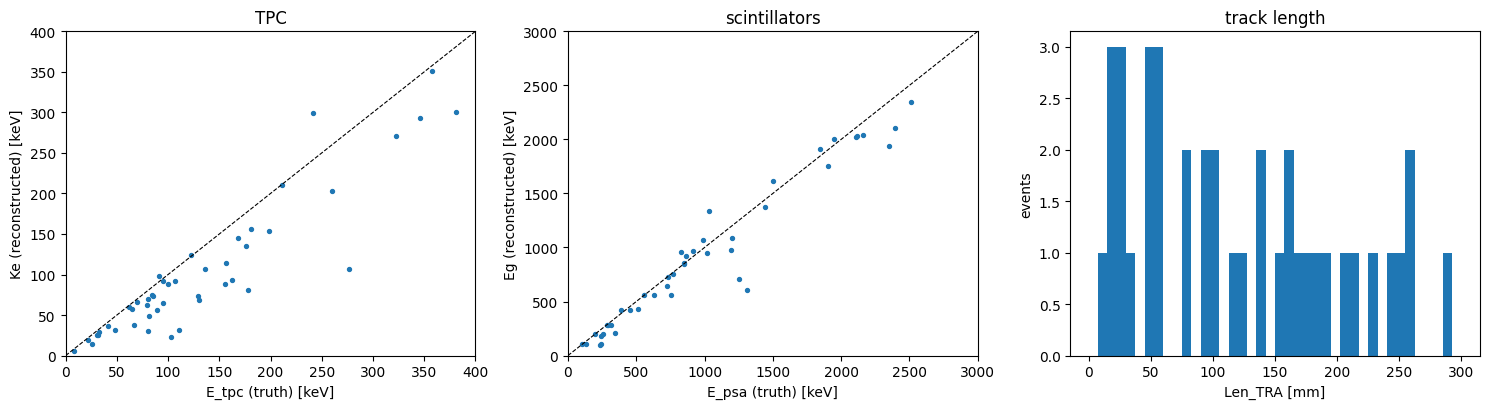

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(truth["E_tpc"][ok], rec["Ke"][ok], s=8)
ax[0].set_xlabel("E_tpc (truth) [keV]"); ax[0].set_ylabel("Ke (reconstructed) [keV]"); ax[0].set_title("TPC")
ax[1].scatter(truth["E_psa"][ok], rec["Eg"][ok], s=8)
ax[1].set_xlabel("E_psa (truth) [keV]"); ax[1].set_ylabel("Eg (reconstructed) [keV]"); ax[1].set_title("scintillators")
for a, lim in zip(ax[:2], [400, 3000]):
    a.plot([0, lim], [0, lim], "k--", lw=0.8); a.set_xlim(0, lim); a.set_ylim(0, lim)
ax[2].hist(rec["Len_TRA"][ok], bins=40, range=(0, 300)); ax[2].set_xlabel("Len_TRA [mm]"); ax[2].set_ylabel("events")
ax[2].set_title("track length")
fig.tight_layout(); plt.show()

- 点線は「再構成 = 真の値」です。シンチ(`Eg`)は、シングルヒット(1 ピクセルだけにエネルギーを落とした)のイベントでは真の値の近くに並びます。
  `E_psa` は全 HA の和なので、複数のピクセルにエネルギーを落としたイベントでは `Eg` の方が小さくなります。
- TPC(`Ke`)は真の値 `E_tpc` より小さめに出ます(この 100 万個では `Ke / E_tpc` の中央値が約 0.8)。
  再構成した `Ke` の分布は SMILE_tool_box の参照のシミュレーションの再構成と一致しているので(`docs/simulation_port_log.md`)、
  SMILE_tool_box と同じ振る舞いで、このチュートリアルではこのまま使います。

> **注意(SMILE-3 に向けた改善事項)**: `Ke` が真の値より系統的に小さいのは、分解能による広がりではなく偏りです。
> エネルギーはすべて読み出しの範囲(x, y が ±150 mm)の中に落ちているので、範囲の外へのもれではありません。
> TPC の応答(電離、増幅、閾値)と較正(`TPC_Calibration`)のどこで小さくなるかを調べ、SMILE-3 では直すべき点です。

- 100 万個では `err_flag == 0` のイベントは数十しかありません。統計を増やすときは `--seed` を変えて何回か実行し
  (1 回 100 万個で約 10 分、並列に実行できる)、raw のディレクトリごとに再構成します。

## 次のステップ

- シミュレーションの設定を変える: `config/README.md`(設定ファイルの書き方)、`run_script/README.md`(`run_sim.py` の引数)
- 再構成ツリーの使い方: `../../tutorials_caldata/2_EventSelection/`、`../../tutorials_caldata/3_Backprojection/`
- 点線源・平行光・宇宙線のシミュレーション: `../2_PointSourceSim/` 〜 `../4_CosmicBGSim/`(準備中)